Importing Required Libraries

In [20]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy.optimize as spop
from datetime import datetime,timedelta
from scipy.stats import norm
from arch import arch_model

Downloading data and Calculating Returns

In [21]:
#specifying sample 
ticker= '^NSEI'
end_date= datetime.today()
start_date= end_date - timedelta(365)

#downloading data
prices= yf.download(ticker, start_date, end_date)['Close'].squeeze()

#calculating returns
returns= np.diff(np.log(prices))

#starting parameter values - sample mean and variance
mean= np.average(returns)
var= np.var(returns)

[*********************100%***********************]  1 of 1 completed


Defining GARCH(1,1) Model

In [22]:
def garch_mle(params):
    #specifying model parameters
    mu= params[0]
    omega= params[1]
    alpha= params[2]
    beta= params[3]

    #enforce GARCH stationarity and positivity constraints
    if omega <= 0 or alpha < 0 or beta < 0 or (alpha + beta) >= 1:
        return 1e15

    #calculating long-run volatility
    long_run= (omega/(1-alpha-beta))**0.5
    
    #calculating realised and conditional volatility
    resid= returns - mu
    realised= abs(resid)
    conditional= np.zeros(len(returns))
    conditional[0]= long_run
    
    for t in range(1,len(returns)):
        conditional[t]= (omega + alpha*resid[t-1]**2 + beta*conditional[t-1]**2)**0.5 

    # calculating log-likelihood
    likelihood= 1/((2*np.pi)**0.5*conditional)*np.exp(-(resid**2)/(2*conditional**2))
    if np.any(likelihood <= 0):
        return 1e15

    log_likelihood= np.sum(np.log(likelihood))
    return float(-log_likelihood)



GARCH(1,1) Model Calibration & Parameter Estimation

In [23]:
#maximizing log likelihood
result= spop.minimize(garch_mle,[mean, var, 0.00,0.00], method='Nelder-Mead')

#retrieving optimal parameters
params= result.x
mu= result.x[0]
omega= result.x[1]
alpha= result.x[2]
beta= result.x[3]
log_likelihood= -float(result.fun)

#calculating realised and conditional volatility for optimal parameters
long_run= (omega/(1-alpha-beta))**0.5
resid= returns - mu
abs_resid= abs(resid)
conditional= np.zeros(len(returns))
conditional[0]= long_run

for t in range(1,len(returns)):
        conditional[t]= (omega + alpha*resid[t-1]**2 + beta*conditional[t-1]**2)**0.5 

#printing optimal parameters
print('GARCH model parameters')
print('')
print('mu ' + str(round(mu, 6)))
print('omega ' + str(round(omega, 6)))
print('alpha ' + str(round(alpha, 4)))
print('beta ' + str(round(beta, 4)))
print('long-run volatility ' + str(round(long_run, 4)))
print('log-likelihood ' + str(round(log_likelihood, 4)))

GARCH model parameters

mu -0.000471
omega 2e-06
alpha 0.0968
beta 0.8663
long-run volatility 0.0079
log-likelihood 839.2059


GARCH(1,1) Volatility Forecasting & Future Projections

In [24]:
#number of days to forecast into the future
n_forecast = 30

#retrieve the final state values from the in-sample fit
last_residual = abs_resid[-1]
last_conditional_var = conditional[-1]**2

#calculate the 1-step-ahead variance forecast
forecast_vars = np.zeros(n_forecast)
forecast_vars[0] = omega + alpha * (last_residual**2) + beta * last_conditional_var

#calculate multi-step-ahead forecasts iteratively
for h in range(1, n_forecast):
    forecast_vars[h] = omega + (alpha + beta) * forecast_vars[h - 1]

#convert variance to daily volatility (standard deviation)
forecast_vol = np.sqrt(forecast_vars)
print(forecast_vol)

#create future dates aligned with the last date of volatility
last_date = prices.index[-1]
future_dates = [last_date + timedelta(days=i) for i in range(1, n_forecast + 1)]

#prepend the last historical point
plot_dates = [last_date] + future_dates
plot_vol = [conditional[-1]] + list(forecast_vol)

[0.00967128 0.00961023 0.00955106 0.00949374 0.0094382  0.0093844
 0.0093323  0.00928184 0.00923299 0.0091857  0.00913992 0.00909561
 0.00905274 0.00901126 0.00897113 0.00893231 0.00889476 0.00885845
 0.00882334 0.0087894  0.00875658 0.00872486 0.0086942  0.00866458
 0.00863595 0.00860828 0.00858156 0.00855574 0.0085308  0.00850672]


visualising the results

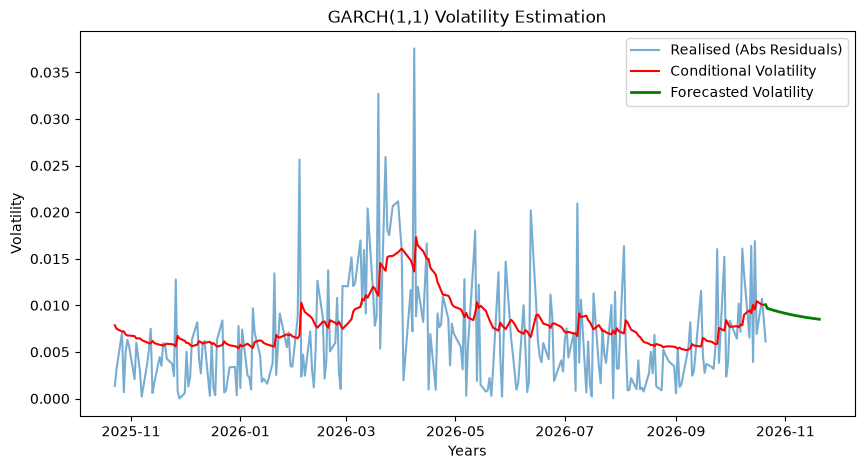

In [25]:
plt.figure(figsize=(10, 5))
plt.rc('xtick', labelsize=10)
plt.plot(prices.index[1:], abs_resid, label='Realised (Abs Residuals)', alpha=0.6)
plt.plot(prices.index[1:], conditional, label='Conditional Volatility', color='red')
plt.plot(plot_dates, plot_vol, label='Forecasted Volatility', color='green', linewidth=2)
plt.legend()
plt.title('GARCH(1,1) Volatility Estimation')
plt.xlabel('Years')
plt.ylabel('Volatility')

plt.show()

**Benchmarking with the ARCH Package**
<br>
<br>
To cross-validate our custom Maximum Likelihood Estimation (MLE) implementation, we fit an equivalent GARCH(1,1) model using Python's production-grade `arch` library. This allows us to compare our custom optimizer's parameters, log-likelihood, and error metrics against an industry-standard package.

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                841.272
Distribution:                  Normal   AIC:                          -1674.54
Method:            Maximum Likelihood   BIC:                          -1660.54
                                        No. Observations:                  245
Date:                Wed, Oct 21 2026   Df Residuals:                      244
Time:                        15:16:59   Df Model:                            1
                                  Mean Model                                  
                  coef    std err          t      P>|t|       95.0% Conf. Int.
------------------------------------------------------------------------------
mu         -4.2547e-04  4.460e-04     -0.954      0.

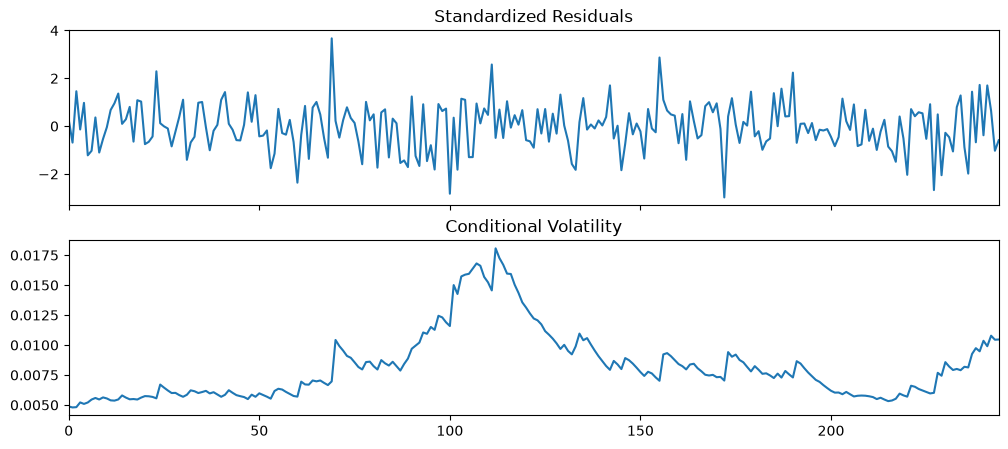

In [26]:
#initialize the GARCH(1,1) model with a constant mean specification
model= arch_model(returns,mean='Constant', vol='GARCH', p=1,q=1, rescale=False)

#fit the model to the returns data via Maximum Likelihood Estimation (suppressing text output)
result= model.fit(disp='off')

#print the full statistical summary (AIC, BIC, coefficients, log-likelihood)
print(result.summary())

#set figure dimensions and plot the conditional volatility and standardized residuals
plt.rcParams['figure.figsize'] = (12, 5)
result.plot()
plt.show()

Value at Risk (VaR) Calculation using GARCH Volatility Forecasts

In [27]:
#choose Confidence Level for VaR
confidence_level = 0.95  # e.g., 95% Confidence
z_score = norm.ppf(confidence_level)

#portfolio Value assumption
portfolio_value = 1000000  # ₹1,000,000 INR

#combines the forecasted conditional mean (`daily_mu`) and conditional volatility (`forecast_vol`) to project potential daily downside risk

daily_mu = mu  # 'mu' from GARCH model

#calculate daily Parametric VaR for each day in specified-days forecast window
annual_var_forecast = portfolio_value * (z_score * forecast_vol - daily_mu)

print(f"---{n_forecast} - DAY HORIZON DAILY GARCH VaR FORECAST (95% Confidence, 1M INR Portfolio) ---")
for day, v in enumerate(annual_var_forecast, 1):
    print(f"Day {day} Projected 1-Day VaR: ₹{v:,.2f}")

---30 - DAY HORIZON DAILY GARCH VaR FORECAST (95% Confidence, 1M INR Portfolio) ---
Day 1 Projected 1-Day VaR: ₹16,378.73
Day 2 Projected 1-Day VaR: ₹16,278.31
Day 3 Projected 1-Day VaR: ₹16,181.00
Day 4 Projected 1-Day VaR: ₹16,086.71
Day 5 Projected 1-Day VaR: ₹15,995.35
Day 6 Projected 1-Day VaR: ₹15,906.86
Day 7 Projected 1-Day VaR: ₹15,821.16
Day 8 Projected 1-Day VaR: ₹15,738.17
Day 9 Projected 1-Day VaR: ₹15,657.82
Day 10 Projected 1-Day VaR: ₹15,580.02
Day 11 Projected 1-Day VaR: ₹15,504.73
Day 12 Projected 1-Day VaR: ₹15,431.85
Day 13 Projected 1-Day VaR: ₹15,361.33
Day 14 Projected 1-Day VaR: ₹15,293.10
Day 15 Projected 1-Day VaR: ₹15,227.09
Day 16 Projected 1-Day VaR: ₹15,163.24
Day 17 Projected 1-Day VaR: ₹15,101.48
Day 18 Projected 1-Day VaR: ₹15,041.76
Day 19 Projected 1-Day VaR: ₹14,984.01
Day 20 Projected 1-Day VaR: ₹14,928.17
Day 21 Projected 1-Day VaR: ₹14,874.19
Day 22 Projected 1-Day VaR: ₹14,822.02
Day 23 Projected 1-Day VaR: ₹14,771.59
Day 24 Projected 1-Day VaR: 